Student Dataset:
   Hours  Marks
0      1     15
1      2     25
2      3     35
3      4     45
4      5     50
5      6     60
6      7     70
7      8     80
8      9     85
9     10     95

Actual Marks: [85, 25]
Predicted Marks: [87.33 25.17]

Mean Absolute Error: 1.25
R2 Score: 1.0



Enter study hours:  12


Predicted Marks: 100.0


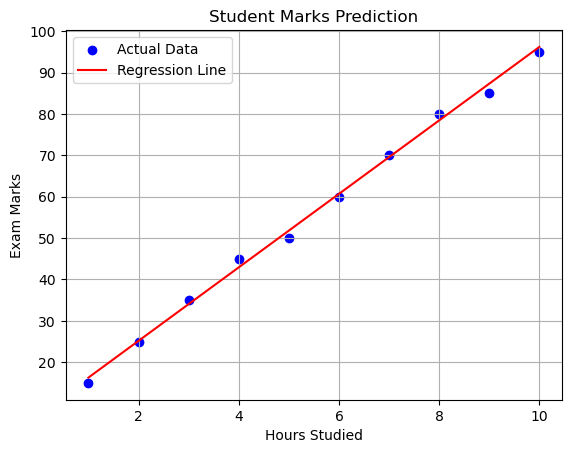

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Step 1: Create the dataset
data = {
    "Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [15, 25, 35, 45, 50, 60, 70, 80, 85, 95]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)

# Step 2: Separate input and output
X = df[["Hours"]]
y = df["Marks"]

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predict test data
y_pred = model.predict(X_test)

print("\nActual Marks:", list(y_test))
print("Predicted Marks:", np.round(y_pred, 2))

# Step 6: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 2))

# Step 7: Get user input
hours = float(input("\nEnter study hours: "))

if 0 <= hours <= 24:
    predicted_marks = model.predict(
        pd.DataFrame({"Hours": [hours]})
    )[0]

    # Marks are displayed within the range 0 to 100
    predicted_marks = np.clip(predicted_marks, 0, 100)

    print("Predicted Marks:", round(predicted_marks, 2))
else:
    print("Please enter hours between 0 and 24.")

# Step 8: Plot the results
plt.scatter(X["Hours"], y, color="blue", label="Actual Data")
plt.plot(
    X["Hours"],
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Marks")
plt.title("Student Marks Prediction")
plt.legend()
plt.grid(True)
plt.show()
